# Lab 2A — 03. Cechy ręczne i Random Forest

Generator propozycji ramek, ekstrakcja cech (geometria, HSV, LBP, krawędzie, HOG), ablacja grup cech na `val` oraz ewaluacja końcowa na `test`.

## Wynik eksperymentu `train/val`

Obliczenia wykonano na `1050` obrazach `train` (39 404 wycinki) i `150` obrazach `val` (11 785 wycinków). Najlepszy wariant: `without_texture` (375 cech, macro F1 wycinków = `0.483`). Próg RF: `0.50` (detekcja na `val`: macro F1 = `0.132`).

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd()

from pathlib import Path
from collections import Counter
from dataclasses import dataclass, asdict
import hashlib
import json
import time

import cv2
import numpy as np
import pandas as pd

CLASSES = ('traffic_sign', 'traffic_light')
COLORS = ('red', 'yellow', 'green', 'unknown')


def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8-sig'))


def save_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding='utf-8')


def load_image(path):
    # imdecode obsługuje polskie znaki w ścieżce także na Windows.
    image = cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f'Nie można odczytać obrazu: {path}')
    return image


def inventory(root, split='train'):
    """Odczytuje nazwy i rozmiary; niczego nie rozpakowuje ani nie modyfikuje."""
    root = Path(root)
    images = {}
    if split not in ('train', 'val', 'test'):
        raise ValueError(split)
    for folder in sorted((root / 'bdd100k_images_100k').glob(f'**/{split}')):
        for path in folder.glob('*.jpg'):
            images[path.stem] = path
    labels = sorted((root / 'bdd100k_labels').glob(f'**/{split}/*.json'))
    pairs = []
    for label in labels:
        image = images.get(label.stem)
        if image is not None and image.stat().st_size > 0 and label.stat().st_size > 0:
            pairs.append({'id': label.stem, 'image': image.relative_to(root).as_posix(),
                          'label': label.relative_to(root).as_posix()})
    return pairs, {'split': split, 'images': len(images), 'labels': len(labels),
                   'paired': len(pairs), 'unpaired_images': len(images.keys() - {p.stem for p in labels}),
                   'unpaired_labels': len(labels) - len(pairs)}


def annotations(path, shape=None):
    """Format dostarczonej wersji: frames[0].objects; wspiera też listę labels."""
    data = read_json(path)
    frames = data.get('frames', [])
    objects = frames[0].get('objects', []) if frames else data.get('labels', [])
    result, problems = [], Counter()
    for obj in objects:
        category = obj.get('category', '').replace(' ', '_')
        if category not in CLASSES:
            continue
        box = obj.get('box2d')
        if not box:
            problems['missing_box'] += 1
            continue
        try:
            coords = np.array([box[k] for k in ('x1', 'y1', 'x2', 'y2')], float)
        except (KeyError, ValueError, TypeError):
            problems['invalid_box'] += 1
            continue
        if not np.isfinite(coords).all() or coords[2] <= coords[0] or coords[3] <= coords[1]:
            problems['invalid_box'] += 1
            continue
        if shape is not None:
            h, w = shape[:2]
            clipped = np.clip(coords, [0, 0, 0, 0], [w, h, w, h])
            if not np.array_equal(clipped, coords):
                problems['clipped_box'] += 1
            coords = clipped
            if coords[2] <= coords[0] or coords[3] <= coords[1]:
                problems['empty_after_clip'] += 1
                continue
        attrs = obj.get('attributes', {})
        color = attrs.get('trafficLightColor', 'unknown')
        if color not in COLORS:
            color = 'unknown'
        result.append({'class': category, 'box': coords.tolist(),
                       'color': color if category == 'traffic_light' else None,
                       'occluded': bool(attrs.get('occluded', False)),
                       'truncated': bool(attrs.get('truncated', False))})
    return result, data.get('attributes', {}), dict(problems)


def make_manifest(root, output, n=1500, seed=42):
    """Podzbiór oficjalnych train/val/test, w proporcji 70/10/20. Bez mieszania."""
    output = Path(output)
    if output.exists():
        manifest = read_json(output)
        if manifest['seed'] != seed or manifest['n'] != n:
            raise ValueError('Istniejący podział ma inne n/seed. Użyj nowego katalogu eksperymentu.')
        return manifest
    if n < 1000:
        raise ValueError('Polecenie wymaga co najmniej 1000 obrazów.')
    sizes = {'train': int(.7*n), 'val': int(.1*n)}
    sizes['test'] = n-sum(sizes.values())
    splits, counts = {}, {}
    rng = np.random.default_rng(seed)
    for split, size in sizes.items():
        pairs, counts[split] = inventory(root, split)
        if len(pairs) < size:
            raise RuntimeError(f'{split}: za mało par: {len(pairs)} / {size}.')
        order = rng.permutation(len(pairs))[:size]
        splits[split] = [pairs[i] for i in order]
        for item in splits[split]:
            image = load_image(Path(root) / item['image'])
            annotations(Path(root) / item['label'], image.shape)
    all_ids = [r['id'] for records in splits.values() for r in records]
    if len(all_ids) != len(set(all_ids)):
        raise ValueError('Powtórzone identyfikatory między oficjalnymi splitami.')
    manifest = {'seed': seed, 'n': n, 'source': 'official_train_val_test',
                'inventory': counts, 'splits': splits}
    save_json(output, manifest)
    return manifest


def iou(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    wh = np.maximum(0, np.minimum(a[2:], b[2:]) - np.maximum(a[:2], b[:2]))
    inter = float(np.prod(wh))
    union = float(np.prod(a[2:]-a[:2]) + np.prod(b[2:]-b[:2]) - inter)
    return inter / union if union > 0 else 0.


def nms(items, threshold=.35):
    kept = []
    for item in sorted(items, key=lambda x: x['score'], reverse=True):
        if all(item['class'] != old['class'] or iou(item['box'], old['box']) <= threshold for old in kept):
            kept.append(item)
    return kept


@dataclass(frozen=True)
class Params:
    saturation: int = 85
    value: int = 65
    sign_min_area: int = 45
    light_min_area: int = 25
    score_threshold: float = .38
    max_y: float = .85


def masks(image, p):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    h, s, v = cv2.split(hsv)
    valid = (s >= p.saturation) & (v >= p.value)
    # OpenCV: H ma zakres 0..179. Czerwony przechodzi przez koniec skali.
    return hsv, {'red': valid & ((h <= 12) | (h >= 165)),
                 'yellow': valid & (h >= 15) & (h <= 38),
                 'green': valid & (h >= 40) & (h <= 95),
                 'blue': valid & (h >= 96) & (h <= 130)}


def contours(mask, close=3):
    mask = np.uint8(mask) * 255
    if close:
        mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((close, close), np.uint8))
    return cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]


def classify_color(crop, p):
    if crop.size == 0:
        return 'unknown'
    _, mm = masks(crop, p)
    scores = {}
    for color in COLORS[:3]:
        areas = [cv2.contourArea(c) for c in contours(mm[color], close=0)]
        scores[color] = max(areas, default=0.)
    ranking = sorted(scores, key=scores.get, reverse=True)
    best, second = ranking[:2]
    if scores[best] < max(2., crop.shape[0]*crop.shape[1]*.006) or scores[best] < 1.4*scores[second]:
        return 'unknown'
    return best


def detect(image, p=Params()):
    """HSV + kontury + geometria. Wszystkie ramki w oryginalnej skali obrazu."""
    h, w = image.shape[:2]
    hsv, mm = masks(image, p)
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    candidates = []
    # Znaki kolorowe oraz jasne tablice (np. ograniczenie prędkości w USA).
    white = (hsv[:, :, 1] < 65) & (hsv[:, :, 2] > 165)
    sign_masks = [mm['red'] | mm['yellow'] | mm['blue'] | mm['green'], white]
    for mask in sign_masks:
        for c in contours(mask):
            x, y, bw, bh = cv2.boundingRect(c)
            area = bw*bh
            if not (p.sign_min_area <= area <= .06*w*h and .35 <= bw/bh <= 3.5 and y < p.max_y*h):
                continue
            fill = cv2.contourArea(c)/area
            hull_area = cv2.contourArea(cv2.convexHull(c))
            solidity = cv2.contourArea(c) / hull_area if hull_area else 0.
            if fill < .4 or solidity < .75:
                continue
            edge = cv2.Canny(gray[y:y+bh, x:x+bw], 70, 150).mean()/255
            if edge < .025:
                continue
            score = float(min(1., .45*fill + .35*min(edge*8, 1) + .2))
            candidates.append({'class': 'traffic_sign', 'box': [x,y,x+bw,y+bh], 'score': score, 'color': None})
    # Obudowy sygnalizatorów: ciemne, zwarte pionowe lub poziome prostokąty.
    dark = gray < 65
    light_boxes = []
    for c in contours(dark):
        x, y, bw, bh = cv2.boundingRect(c)
        if not (p.light_min_area <= bw*bh <= .025*w*h and y < p.max_y*h):
            continue
        ratio = bw/bh
        if not (.18 <= ratio <= .8 or 1.5 <= ratio <= 5.):
            continue
        fill = cv2.contourArea(c)/(bw*bh)
        if fill >= .4:
            light_boxes.append(([x,y,x+bw,y+bh], fill, False))
    # Mała świecąca lampa może nie połączyć się z obudową w masce ciemności.
    # Rozszerzenie to hipoteza geometrii, nie ramka referencyjna.
    # Świecące punkty muszą być jaśniejsze i bardziej nasycone niż zwykły znak.
    lamp_valid = (hsv[:,:,1] >= max(p.saturation,110)) & (hsv[:,:,2] >= 155)
    for color in COLORS[:3]:
        for c in contours(mm[color] & lamp_valid, close=0):
            x,y,bw,bh = cv2.boundingRect(c)
            fill = cv2.contourArea(c)/(bw*bh)
            if 5 <= bw*bh <= 500 and .55 <= bw/bh <= 1.8 and fill >= .45 and y < p.max_y*h:
                for shift in (0., 1., 2.):
                    light_boxes.append(([x-.4*bw,y-shift*bh,x+1.4*bw,y+(3-shift)*bh], .5, True))
    for box, fill, expanded in light_boxes:
        x1,y1,x2,y2 = np.clip(box, [0,0,0,0], [w,h,w,h]).astype(int)
        crop = image[y1:y2,x1:x2]
        if expanded and (crop.size == 0 or np.mean(cv2.cvtColor(crop,cv2.COLOR_BGR2GRAY) < 85) < .35):
            continue
        color = classify_color(crop, p)
        score = float(.25 + .25*fill + (.3 if color != 'unknown' else 0) - (.05 if expanded else 0))
        candidates.append({'class': 'traffic_light', 'box': [int(x1),int(y1),int(x2),int(y2)],
                           'score': score, 'color': color})
    return nms([item for item in candidates if item['score'] >= p.score_threshold])


def match(pred, gt, category, threshold=.5):
    """Greedy po score; jeden GT najwyżej raz. Kolor nie wpływa na dopasowanie."""
    pi = sorted([i for i,p in enumerate(pred) if p['class']==category], key=lambda i: -pred[i]['score'])
    remaining = {i for i,g in enumerate(gt) if g['class']==category}
    matches, fp = [], []
    for i in pi:
        j = max(remaining, key=lambda j: (iou(pred[i]['box'], gt[j]['box']), -j), default=None)
        if j is not None and iou(pred[i]['box'], gt[j]['box']) >= threshold:
            matches.append((i,j))
            remaining.remove(j)
        else:
            fp.append(i)
    return matches, fp, sorted(remaining)


def evaluate(root, records, p, predictions=None):
    rows, errors, color_pairs, saved = [], [], [], {}
    counts = {c: Counter(TP=0, FP=0, FN=0) for c in CLASSES}
    started = time.perf_counter()
    for record in records:
        image = load_image(Path(root)/record['image'])
        gt, _, _ = annotations(Path(root)/record['label'], image.shape)
        pred = predictions[record['id']] if predictions is not None else detect(image, p)
        saved[record['id']] = pred
        for category in CLASSES:
            matched, fp, fn = match(pred, gt, category)
            counts[category].update(TP=len(matched), FP=len(fp), FN=len(fn))
            for pi, gi in matched:
                if category == 'traffic_light':
                    color_pairs.append((gt[gi]['color'], pred[pi]['color']))
            for index in fp:
                errors.append({'id':record['id'], 'type':'FP', 'class':category, 'box':pred[index]['box']})
            for index in fn:
                errors.append({'id':record['id'], 'type':'FN', 'class':category, 'box':gt[index]['box']})
    for category, c in counts.items():
        tp, fp, fn = c['TP'], c['FP'], c['FN']
        rows.append({'class':category, **c, 'precision':tp/(tp+fp) if tp+fp else 0.,
                     'recall':tp/(tp+fn) if tp+fn else 0.,
                     'F1':2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.})
    matrix = pd.DataFrame(0, index=COLORS, columns=COLORS)
    for actual, predicted in color_pairs:
        matrix.loc[actual, predicted] += 1
    return {'metrics':pd.DataFrame(rows), 'confusion':matrix, 'errors':errors, 'predictions':saved,
            'seconds':time.perf_counter()-started, 'matched_lights':len(color_pairs),
            'color_accuracy':sum(a==b for a,b in color_pairs)/len(color_pairs) if color_pairs else None}


def draw(image, boxes, title='', ax=None):
    import matplotlib.pyplot as plt
    from matplotlib.patches import Rectangle
    if ax is None:
        _, ax = plt.subplots(figsize=(14,8))
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    for item in boxes:
        x1,y1,x2,y2 = item['box']
        color = 'lime' if item['class']=='traffic_sign' else 'cyan'
        ax.add_patch(Rectangle((x1,y1), x2-x1,y2-y1,fill=False,edgecolor=color,linewidth=1.3))
        label = item['class'] + (f"/{item['color']}" if item.get('color') else '')
        ax.text(x1,y1,label,color='black',fontsize=6,bbox={'facecolor':color,'alpha':.7,'pad':1})
    ax.set(title=title)
    ax.axis('off')
    return ax


def fingerprint(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()
N, SEED = 1500, 42
EXP = ROOT/'outputs'/f'official_{N}_seed{SEED}'
manifest = make_manifest(ROOT,EXP/'manifest.json',N,SEED)
assert manifest['source']=='official_train_val_test', 'Użyj manifestu oficjalnych splitów.'
splits = manifest['splits']
print('Podział:',{k:len(v) for k,v in splits.items()})
print('Wyniki:',EXP)

import inspect
from pathlib import Path
import time
import cv2
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score


LABELS = ('background', 'traffic_sign', 'traffic_light')
FEATURE_VERSION = 'handcrafted_v1'


def local_hog(magnitude, angle):
    """324 cechy HOG: komórki 8×8, bloki 2×2, 9 kierunków, L2-Hys.

    Jawna implementacja z interpolacją kierunku, bez interpolacji przestrzennej.
    Nie zależy od dostępności HOGDescriptor w konkretnej dystrybucji OpenCV.
    """
    bins = (angle % 180) / 20
    lower = bins.astype(int) % 9
    fraction = bins-np.floor(bins)
    yy,xx = np.indices(magnitude.shape)
    hist = np.zeros((4,4,9),np.float32)
    np.add.at(hist,(yy//8,xx//8,lower),magnitude*(1-fraction))
    np.add.at(hist,(yy//8,xx//8,(lower+1)%9),magnitude*fraction)
    blocks = []
    for y in range(3):
        for x in range(3):
            vector = hist[y:y+2,x:x+2].ravel().copy()
            vector /= np.sqrt(np.dot(vector,vector)+1e-6)
            vector = np.minimum(vector,.2)
            vector /= np.sqrt(np.dot(vector,vector)+1e-6)
            blocks.extend(vector)
    return np.asarray(blocks,dtype=np.float32)


def proposals(image, limit=100):
    """HSV/ciemne obudowy oraz krawędzie; nie otrzymuje etykiet ani GT."""
    h,w = image.shape[:2]
    base = detect(image, Params(saturation=65, sign_min_area=25,
                                light_min_area=16, score_threshold=0., max_y=1.))
    # Maksymalnie 60 hipotez z masek i 40 z konturów krawędzi.
    boxes = [p['box'] for p in sorted(base, key=lambda p:-p['score'])[:60]]
    gray = cv2.cvtColor(image,cv2.COLOR_BGR2GRAY)
    edges = cv2.Canny(gray,70,160)
    extras = []
    for c in contours(edges > 0):
        x,y,bw,bh = cv2.boundingRect(c)
        if 24 <= bw*bh <= .06*w*h and .15 <= bw/bh <= 5. and min(bw,bh)>=3:
            extras.append((cv2.arcLength(c,True)/(bw+bh), [x,y,x+bw,y+bh]))
    boxes += [b for _,b in sorted(extras,key=lambda p:-p[0])[:40]]
    unique = []
    for box in boxes:
        if all(iou(box,old)<.9 for old in unique):
            unique.append(box)
        if len(unique)>=limit:
            break
    return unique


def features(image, box):
    """Stała kolejność nazw. Zwraca jedynie wielkości mierzone na obrazie."""
    h,w = image.shape[:2]
    x1,y1,x2,y2 = np.clip(box,[0,0,0,0],[w,h,w,h]).astype(int)
    if x2<=x1 or y2<=y1:
        raise ValueError(f'Pusta ramka {box}')
    crop = image[y1:y2,x1:x2]
    small = cv2.resize(crop,(32,32),interpolation=cv2.INTER_AREA)
    gray = cv2.cvtColor(small,cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(small,cv2.COLOR_BGR2HSV)
    hh,ss,vv = cv2.split(hsv)
    f = {'geometry.width':(x2-x1)/w, 'geometry.height':(y2-y1)/h,
         'geometry.aspect':(x2-x1)/(y2-y1), 'geometry.area':(x2-x1)*(y2-y1)/(w*h),
         'geometry.center_x':(x1+x2)/(2*w), 'geometry.center_y':(y1+y2)/(2*h)}
    for channel, name, bins, upper in [(hh,'h',12,180),(ss,'s',8,256),(vv,'v',8,256)]:
        hist = np.histogram(channel,bins=bins,range=(0,upper))[0]/channel.size
        f.update({f'color.{name}_hist_{i:02}':float(v) for i,v in enumerate(hist)})
    saturated = (ss>75)&(vv>70)
    for name, mask in [('red',((hh<13)|(hh>164))&saturated),
                       ('yellow',(hh>=15)&(hh<=38)&saturated),
                       ('green',(hh>=40)&(hh<=95)&saturated),
                       ('blue',(hh>=96)&(hh<=130)&saturated),
                       ('white',(ss<65)&(vv>165)),('dark',vv<65)]:
        f[f'color.fraction_{name}'] = float(mask.mean())
    # Uniform LBP, 8 sąsiadów: liczba zmian 0/1 <=2 -> liczba jedynek, inaczej bin 9.
    center = gray[1:-1,1:-1]
    neighbors = [gray[:-2,:-2],gray[:-2,1:-1],gray[:-2,2:],gray[1:-1,2:],
                 gray[2:,2:],gray[2:,1:-1],gray[2:,:-2],gray[1:-1,:-2]]
    bits = np.stack([n>=center for n in neighbors])
    transitions = (bits != np.roll(bits,1,axis=0)).sum(axis=0)
    codes = np.where(transitions<=2,bits.sum(axis=0),9)
    hist = np.bincount(codes.ravel(),minlength=10)/codes.size
    f.update({f'texture.lbp_{i:02}':float(v) for i,v in enumerate(hist)})
    f['texture.gray_std'] = float(gray.std()/255)
    f['texture.laplacian_var'] = float(cv2.Laplacian(gray,cv2.CV_32F).var()/255**2)
    gx = cv2.Sobel(gray,cv2.CV_32F,1,0)
    gy = cv2.Sobel(gray,cv2.CV_32F,0,1)
    magnitude, angle = cv2.cartToPolar(gx,gy,angleInDegrees=True)
    hist = np.histogram(angle%180,bins=9,range=(0,180),weights=magnitude)[0]
    hist = hist/(hist.sum()+1e-8)
    f.update({f'edges.orientation_{i:02}':float(v) for i,v in enumerate(hist)})
    f['edges.density'] = float((cv2.Canny(gray,70,150)>0).mean())
    f['edges.magnitude'] = float(magnitude.mean()/1020)
    f.update({f'hog.bin_{i:03}':float(v) for i,v in enumerate(local_hog(magnitude,angle))})
    return f


def assign_label(box, truth):
    if not truth:
        return 'background'
    overlaps = [iou(box,g['box']) for g in truth]
    best = int(np.argmax(overlaps))
    if overlaps[best]>=.5:
        return truth[best]['class']
    return 'background' if max(overlaps)<=.2 else None


def feature_table(root, records, training, seed=42, limit=100, cache=None):
    """Train: GT+jitter+kandydaci+tło. Val: wyłącznie rzeczywiste propozycje."""
    root = Path(root)
    signature = {'version':FEATURE_VERSION, 'records':fingerprint(records),
                 'training':training, 'seed':seed, 'limit':limit,
                 'code':hashlib.sha256((FEATURE_VERSION + ''.join(inspect.getsource(fn) for fn in (local_hog, proposals, features, assign_label, feature_table))).encode()).hexdigest()}
    if cache:
        cache = Path(cache)
        if cache.with_suffix('.json').exists() and cache.with_suffix('.npz').exists():
            if read_json(cache.with_suffix('.json')) == signature:
                data = np.load(cache.with_suffix('.npz'),allow_pickle=False)
                return pd.DataFrame(data['X'],columns=data['columns']), data['y'], data['groups']
    rng = np.random.default_rng(seed)
    rows, targets, groups = [],[],[]
    for number, record in enumerate(records):
        image = load_image(root/record['image'])
        truth,_,_ = annotations(root/record['label'],image.shape)
        candidates = proposals(image,limit)
        if training:
            # GT używamy tylko do konstrukcji uczących wycinków, nigdy w detekcji.
            positives = []
            for obj in truth:
                positives.append(obj['box'])
                b = np.array(obj['box'],float)
                bw,bh = b[2:]-b[:2]
                jitter = b+rng.uniform(-.1,.1,4)*np.array([bw,bh,bw,bh])
                jitter = np.clip(jitter,[0,0,0,0],[image.shape[1],image.shape[0]]*2)
                if iou(jitter,b)>=.5:
                    positives.append(jitter.tolist())
            # Losowe tło obejmuje także obrazy bez znaków i świateł.
            h,w = image.shape[:2]
            for _ in range(20):
                bw = int(rng.integers(6,max(7,w//8)))
                bh = int(rng.integers(6,max(7,h//6)))
                x = int(rng.integers(0,w-bw+1)); y = int(rng.integers(0,h-bh+1))
                candidates.append([x,y,x+bw,y+bh])
            negatives = [b for b in candidates if assign_label(b,truth)=='background']
            if len(negatives)>24:
                negatives = [negatives[i] for i in rng.choice(len(negatives),24,replace=False)]
            detected_positive = [b for b in candidates if assign_label(b,truth) in LABELS[1:]]
            candidates = positives+detected_positive+negatives
        for box in candidates:
            label = assign_label(box,truth)
            if label is None:
                continue  # niejednoznaczny wycinek, 0.2 < IoU < 0.5
            rows.append(features(image,box)); targets.append(label); groups.append(record['id'])
        if (number+1)%100==0:
            print(f'Cechy: {number+1}/{len(records)} obrazów; {len(rows)} wycinków',flush=True)
    if not rows:
        raise ValueError('Brak wycinków do analizy.')
    X = pd.DataFrame(rows,dtype=np.float32)
    y = np.asarray(targets,dtype=str); groups = np.asarray(groups,dtype=str)
    if cache:
        cache.parent.mkdir(parents=True,exist_ok=True)
        np.savez_compressed(cache.with_suffix('.npz'),X=X.to_numpy(),y=y,groups=groups,
                            columns=np.asarray(X.columns,dtype=str))
        save_json(cache.with_suffix('.json'),signature)
    return X,y,groups


def train_forest(X,y,seed=42):
    missing = set(LABELS)-set(y)
    if missing:
        raise ValueError(f'Brak klas w danych uczących: {missing}. Zwiększ train.')
    model = RandomForestClassifier(n_estimators=100,max_depth=18,min_samples_leaf=2,
                                   max_features='sqrt',class_weight='balanced_subsample',
                                   random_state=seed,n_jobs=-1)
    model.fit(X,y)
    return model


def macro_f1(y,pred):
    return f1_score(y,pred,labels=list(LABELS),average='macro',zero_division=0)


def compare_groups(X,y,V,vy,seed=42):
    """Ablacja: te same train/val i hiperparametry, inna lista cech."""
    groups = list(dict.fromkeys(c.split('.')[0] for c in X.columns))
    variants = {g:[c for c in X if c.startswith(g+'.')] for g in groups}
    variants['color+geometry'] = [c for c in X if c.split('.')[0] in ('color','geometry')]
    variants['all'] = list(X.columns)
    variants.update({'without_'+g:[c for c in X if not c.startswith(g+'.')] for g in groups})
    rows,models = [],{}
    for name,columns in variants.items():
        start = time.perf_counter()
        model = train_forest(X[columns],y,seed)
        pred = model.predict(V[columns])
        rows.append({'variant':name,'features':len(columns),'val_crop_macro_F1':macro_f1(vy,pred),
                     'seconds':time.perf_counter()-start})
        models[name] = (model,columns)
        print(name,round(rows[-1]['val_crop_macro_F1'],4),flush=True)
    return pd.DataFrame(rows).sort_values('val_crop_macro_F1',ascending=False),models


def permutation_groups(model,X,y,repeats=3,seed=42):
    """Mieszamy wszystkie kolumny grupy jednym porządkiem, zachowując jej wnętrze."""
    rng = np.random.default_rng(seed)
    baseline = macro_f1(y,model.predict(X))
    rows = []
    for group in dict.fromkeys(c.split('.')[0] for c in X.columns):
        columns = [c for c in X if c.startswith(group+'.')]
        drops = []
        for _ in range(repeats):
            shuffled = X.copy()
            shuffled.loc[:,columns] = X[columns].to_numpy()[rng.permutation(len(X))]
            drops.append(baseline-macro_f1(y,model.predict(shuffled)))
        rows.append({'group':group,'mean_F1_drop':float(np.mean(drops)),
                     'std_F1_drop':float(np.std(drops)),'features':len(columns)})
    return pd.DataFrame(rows).sort_values('mean_F1_drop',ascending=False)


def rf_detect(image,model,columns,threshold=.5,limit=100):
    boxes = proposals(image,limit)
    if not boxes:
        return []
    X = pd.DataFrame([features(image,b) for b in boxes],dtype=np.float32)[columns]
    probabilities = model.predict_proba(X)
    items = []
    for box,probs in zip(boxes,probabilities):
        index = int(np.argmax(probs))
        category = model.classes_[index]
        score = float(probs[index])
        if category=='background' or score<threshold:
            continue
        x1,y1,x2,y2 = map(int,box)
        color = classify_color(image[y1:y2,x1:x2],Params()) if category=='traffic_light' else None
        items.append({'class':str(category),'box':box,'score':score,'color':color})
    return nms(items)


def predict_records(root,records,model,columns,threshold=.5,limit=100):
    predictions = {}
    for i,record in enumerate(records):
        predictions[record['id']] = rf_detect(load_image(Path(root)/record['image']),model,columns,threshold,limit)
        if (i+1)%50==0:
            print(f'Detekcja RF: {i+1}/{len(records)}',flush=True)
    return predictions


def proposal_recall(root,records,limit=100):
    """Sufit recall dla tych propozycji: bez poprawnej ramki RF nie ma szans."""
    counts = {c:[0,0] for c in LABELS[1:]}
    for record in records:
        image = load_image(Path(root)/record['image'])
        truth,_,_ = annotations(Path(root)/record['label'],image.shape)
        boxes = proposals(image,limit)
        for obj in truth:
            counts[obj['class']][1] += 1
            counts[obj['class']][0] += int(any(iou(b,obj['box'])>=.5 for b in boxes))
    return pd.DataFrame([{'class':c,'covered_GT':a,'all_GT':b,'proposal_recall':a/b if b else 0.}
                         for c,(a,b) in counts.items()])
from sklearn.metrics import classification_report
import joblib
RF_DIR = EXP/'features_rf'; RF_DIR.mkdir(parents=True,exist_ok=True)
PROPOSAL_LIMIT = 100

Podział: {'train': 1050, 'val': 150, 'test': 300}
Wyniki: c:\Users\hubi_\Desktop\Dane\Studia\AGH\III sem\Rozpoznawanie wzorców\lab4\outputs\official_1500_seed42


## Generator propozycji ramek

,class,covered_GT,all_GT,proposal_recall
0,traffic_sign,105,474,0.221519
1,traffic_light,70,413,0.169492


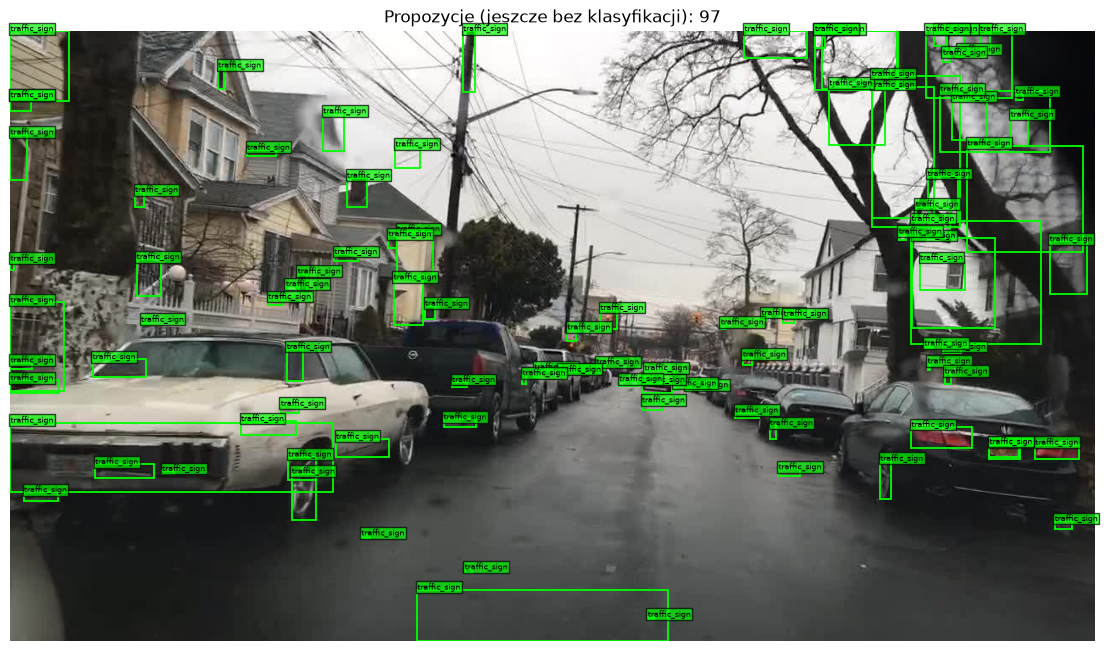

In [2]:
coverage = proposal_recall(ROOT,splits['val'],PROPOSAL_LIMIT)
display(coverage)
coverage.to_csv(RF_DIR/'val_proposal_recall.csv',index=False)
r = splits['train'][0]; im = load_image(ROOT/r['image'])
boxes = proposals(im,PROPOSAL_LIMIT)
preview = [{'class':'traffic_sign','box':b,'color':None} for b in boxes]
draw(im,preview,f'Propozycje (jeszcze bez klasyfikacji): {len(boxes)}')
plt.show()

## Ekstrakcja cech (32×32 px)

In [3]:
sample = features(im,boxes[0] if boxes else [0,0,32,32])
schema = pd.DataFrame({'feature':list(sample),'example_value':list(sample.values())})
schema['group'] = schema.feature.str.split('.').str[0]
display(schema.groupby('group').size().rename('liczba cech').to_frame())
display(schema.head(15))
schema.to_csv(RF_DIR/'feature_schema.csv',index=False)
X,y,train_groups = feature_table(ROOT,splits['train'],True,SEED,PROPOSAL_LIMIT,RF_DIR/'train_features')
V,vy,val_groups = feature_table(ROOT,splits['val'],False,SEED,PROPOSAL_LIMIT,RF_DIR/'val_features')
assert list(X.columns)==list(V.columns)
assert set(train_groups).isdisjoint(set(val_groups))
assert np.isfinite(X.to_numpy()).all() and np.isfinite(V.to_numpy()).all()
display(pd.DataFrame({'train':pd.Series(y).value_counts(),'val':pd.Series(vy).value_counts()}).fillna(0))
print('Macierze:',X.shape,V.shape)
if not set(LABELS).issubset(set(vy)):
    print('UWAGA: nie wszystkie klasy występują w kandydatach val. Interpretuj ranking ostrożnie.')

,liczba cech
group,
color,34
edges,11
geometry,6
hog,324
texture,12


,feature,example_value,group
0,geometry.width,0.057813,geometry
1,geometry.height,0.044444,geometry
2,geometry.aspect,2.312500,geometry
3,geometry.area,0.002569,geometry
4,geometry.center_x,0.705469,geometry
5,geometry.center_y,0.022222,geometry
6,color.h_hist_00,0.598633,color
7,color.h_hist_01,0.102539,color
8,color.h_hist_02,0.001953,color
9,color.h_hist_03,0.000000,color


Cechy: 100/1050 obrazów; 3807 wycinków
Cechy: 200/1050 obrazów; 7583 wycinków
Cechy: 300/1050 obrazów; 11362 wycinków
Cechy: 400/1050 obrazów; 15074 wycinków
Cechy: 500/1050 obrazów; 18856 wycinków
Cechy: 600/1050 obrazów; 22475 wycinków
Cechy: 700/1050 obrazów; 26335 wycinków
Cechy: 800/1050 obrazów; 30129 wycinków
Cechy: 900/1050 obrazów; 33814 wycinków
Cechy: 1000/1050 obrazów; 37442 wycinków
Cechy: 100/150 obrazów; 7825 wycinków


,train,val
background,25200,11596
traffic_sign,7951,115
traffic_light,6253,74


Macierze: (39404, 387) (11785, 387)


## Trening i ablacja zestawów cech (`val`)

geometry 0.3181
color 0.3969
texture 0.3254
edges 0.3314
hog 0.4216
color+geometry 0.4141
all 0.4681
without_geometry 0.4502
without_color 0.4346
without_texture 0.4826
without_edges 0.4748
without_hog 0.4309


,variant,features,val_crop_macro_F1,seconds
9,without_texture,375,0.482625,11.538360
10,without_edges,376,0.474849,10.487403
6,all,387,0.468095,14.768242
7,without_geometry,381,0.450176,13.347907
8,without_color,353,0.434639,12.084835
11,without_hog,63,0.430907,3.640868
4,hog,324,0.421601,13.936738
5,color+geometry,40,0.414053,2.712996
1,color,34,0.396878,1.190434
3,edges,11,0.331379,1.512007


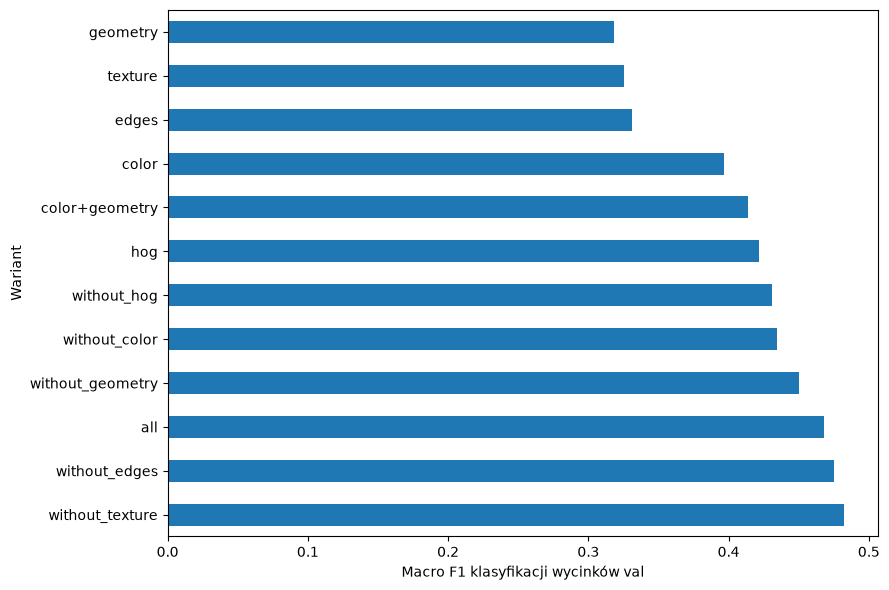

               precision    recall  f1-score   support

   background       0.99      0.93      0.96     11596
 traffic_sign       0.16      0.63      0.25       115
traffic_light       0.11      0.65      0.19        74

     accuracy                           0.93     11785
    macro avg       0.42      0.74      0.47     11785
 weighted avg       0.98      0.93      0.95     11785



In [4]:
ablation,models = compare_groups(X,y,V,vy,SEED)
display(ablation)
ablation.to_csv(RF_DIR/'val_group_ablation.csv',index=False)
ax = ablation.set_index('variant').val_crop_macro_F1.plot.barh(figsize=(9,6))
ax.set(xlabel='Macro F1 klasyfikacji wycinków val',ylabel='Wariant')
plt.tight_layout(); plt.savefig(RF_DIR/'ablation.png',dpi=140); plt.show()
full_model,full_columns = models['all']
print(classification_report(vy,full_model.predict(V),labels=list(LABELS),zero_division=0))

## Ważność cech (MDI i permutacja)

,feature,MDI
5,geometry.center_y,0.039617
2,geometry.aspect,0.039259
0,geometry.width,0.024548
33,color.v_hist_07,0.016167
3,geometry.area,0.015670
32,color.v_hist_06,0.014236
36,color.fraction_green,0.013267
48,texture.lbp_08,0.012409
31,color.v_hist_05,0.012282
23,color.s_hist_05,0.012059


,group,mean_F1_drop,std_F1_drop,features
4,hog,0.089103,0.019816,324
1,color,0.064693,0.027121,34
0,geometry,0.040497,0.018712,6
2,texture,0.005357,0.010724,12
3,edges,-0.036253,0.007069,11


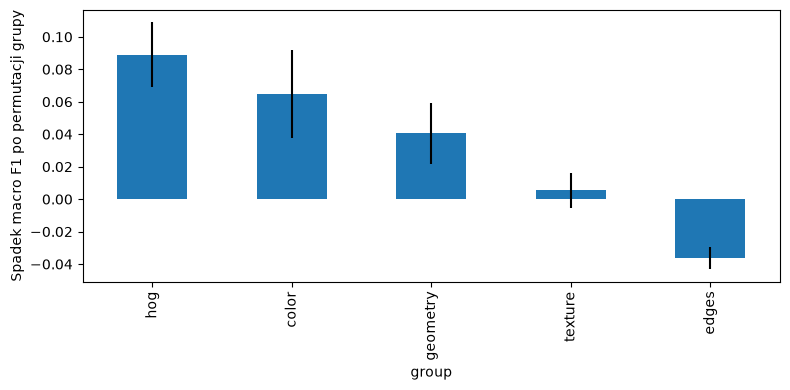

,feature,mean_F1_drop,std_F1_drop
0,geometry.center_y,0.021119,0.009795
11,color.s_hist_04,0.005882,0.006863
6,color.fraction_green,-0.000350,0.003427
3,color.v_hist_07,-0.000445,0.002478
15,edges.orientation_00,-0.000712,0.002836
14,color.s_hist_06,-0.001095,0.000978
19,texture.lbp_04,-0.001829,0.003843
8,color.v_hist_05,-0.002130,0.004133
4,geometry.area,-0.002322,0.002630
17,color.fraction_white,-0.002737,0.002532


In [5]:
mdi = pd.DataFrame({'feature':X.columns,'MDI':full_model.feature_importances_}).sort_values('MDI',ascending=False)
display(mdi.head(25))
mdi.to_csv(RF_DIR/'feature_MDI.csv',index=False)
# Ograniczamy koszt permutacji do stałego losowego podzbioru val.
rng = np.random.default_rng(SEED)
take = rng.choice(len(V),size=min(1500,len(V)),replace=False)
importance = permutation_groups(full_model,V.iloc[take],vy[take],repeats=3,seed=SEED)
display(importance)
importance.to_csv(RF_DIR/'val_group_permutation.csv',index=False)
importance.set_index('group').mean_F1_drop.plot.bar(yerr=importance.std_F1_drop.to_numpy(),figsize=(8,4))
plt.ylabel('Spadek macro F1 po permutacji grupy'); plt.tight_layout()
plt.savefig(RF_DIR/'group_permutation.png',dpi=140); plt.show()
# Top 20 MDI sprawdzamy także osobno przez permutację na val.
base_score = macro_f1(vy[take],full_model.predict(V.iloc[take]))
individual = []
for name in mdi.feature.head(20):
    drops = []
    for _ in range(3):
        shuffled = V.iloc[take].copy()
        shuffled[name] = shuffled[name].to_numpy()[rng.permutation(len(take))]
        drops.append(base_score-macro_f1(vy[take],full_model.predict(shuffled)))
    individual.append({'feature':name,'mean_F1_drop':np.mean(drops),'std_F1_drop':np.std(drops)})
individual = pd.DataFrame(individual).sort_values('mean_F1_drop',ascending=False)
display(individual)
individual.to_csv(RF_DIR/'val_top20_individual_permutation.csv',index=False)

## Dobór progu detekcji (`val`)

In [6]:
chosen_name = ablation.sort_values(['val_crop_macro_F1','features','variant'],ascending=[False,True,True]).iloc[0]['variant']
model,columns = models[chosen_name]
val_raw = predict_records(ROOT,splits['val'],model,columns,.0,PROPOSAL_LIMIT)
threshold_rows = []
for threshold in [.35,.5,.65,.8]:
    pred = {name:[p for p in ps if p['score']>=threshold] for name,ps in val_raw.items()}
    result = evaluate(ROOT,splits['val'],Params(),predictions=pred)
    threshold_rows.append({'threshold':threshold,'val_detection_macro_F1':result['metrics'].F1.mean()})
thresholds = pd.DataFrame(threshold_rows).sort_values(['val_detection_macro_F1','threshold'],ascending=[False,True])
display(thresholds)
thresholds.to_csv(RF_DIR/'val_thresholds.csv',index=False)
threshold = float(thresholds.iloc[0].threshold)
lock = {'manifest_sha256':fingerprint(manifest),'variant':str(chosen_name),'columns':columns,
        'threshold':threshold,'proposal_limit':PROPOSAL_LIMIT,'seed':SEED,
        'feature_code_sha256':hashlib.sha256(inspect.getsource(features).encode()).hexdigest(),
        'classical_code_sha256':hashlib.sha256(inspect.getsource(detect).encode()).hexdigest()}
if (RF_DIR/'locked_rf.json').exists():
    existing_lock = read_json(RF_DIR/'locked_rf.json')
    assert all(existing_lock.get(k)==lock[k] for k in ('manifest_sha256','variant','columns','threshold','proposal_limit','seed')), 'Eksperyment już zamrożony z innymi ustawieniami.'
else:
    save_json(RF_DIR/'locked_rf.json',lock)
    joblib.dump(model,RF_DIR/'random_forest.joblib')
print('Wybrano:',chosen_name,'; próg:',threshold)

Detekcja RF: 50/150
Detekcja RF: 100/150
Detekcja RF: 150/150


,threshold,val_detection_macro_F1
1,0.50,0.131723
0,0.35,0.129465
2,0.65,0.091449
3,0.80,0.026717


Wybrano: without_texture ; próg: 0.5


## Ewaluacja końcowa na `test` i porównanie z baseline

In [7]:
lock = read_json(RF_DIR/'locked_rf.json')
assert lock['manifest_sha256']==fingerprint(manifest)
pred_path = RF_DIR/'test_predictions.json'
if pred_path.exists():
    saved = read_json(pred_path)
    assert saved['metadata']==lock
    test_predictions = saved['predictions']
else:
    test_predictions = predict_records(ROOT,splits['test'],model,columns,threshold,PROPOSAL_LIMIT)
    save_json(pred_path,{'metadata':lock,'predictions':test_predictions})
assert set(test_predictions)=={r['id'] for r in splits['test']}
final = evaluate(ROOT,splits['test'],Params(),predictions=test_predictions)
display(final['metrics']); display(final['confusion'])
print('Accuracy koloru na TP:',final['color_accuracy'],'; liczba TP lamp:',final['matched_lights'])
final['metrics'].to_csv(RF_DIR/'test_metrics.csv',index=False)
final['confusion'].to_csv(RF_DIR/'test_color_confusion.csv',index_label='GT / prediction')
save_json(RF_DIR/'test_errors.json',final['errors'])
save_json(RF_DIR/'test_summary.json',{'metadata':lock,'matched_lights':final['matched_lights'],
                                    'color_accuracy':final['color_accuracy']})
baseline_path = EXP/'test_metrics.csv'
if baseline_path.exists():
    comparison = pd.concat([pd.read_csv(baseline_path).assign(method='HSV'),
                            final['metrics'].assign(method='features+RF')],ignore_index=True)
    display(comparison); comparison.to_csv(RF_DIR/'test_comparison.csv',index=False)
else:
    print('Porównanie HSV pojawi się po wykonaniu notebooka 02 na tym samym manifeście.')

Detekcja RF: 50/300
Detekcja RF: 100/300
Detekcja RF: 150/300
Detekcja RF: 200/300
Detekcja RF: 250/300
Detekcja RF: 300/300


,class,TP,FP,FN,precision,recall,F1
0,traffic_sign,84,348,893,0.194444,0.085977,0.119233
1,traffic_light,64,342,720,0.157635,0.081633,0.107563


,red,yellow,green,unknown
red,9,0,0,1
yellow,0,0,0,0
green,0,2,43,0
unknown,1,8,0,0


Accuracy koloru na TP: 0.8125 ; liczba TP lamp: 64


,class,TP,FP,FN,precision,recall,F1,method
0,traffic_sign,156,5428,821,0.027937,0.159672,0.047554,HSV
1,traffic_light,21,2476,763,0.008410,0.026786,0.012801,HSV
2,traffic_sign,84,348,893,0.194444,0.085977,0.119233,features+RF
3,traffic_light,64,342,720,0.157635,0.081633,0.107563,features+RF


## Wnioski